<a href="https://colab.research.google.com/github/AlejandroC-25/Ciencia-y-analitica-de-datos-A00835060-/blob/main/Actividad5Preprocesamiento.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 5**
Preprocesamiento de datos

---

*   NOMBRE: Alejandro Cena Peart
*   MATRÍCULA: A00835060

En esta actividad trabajarás con el archivo `heart_disease.csv`, basado en un conjunto de datos sobre pacientes y variables clínicas relacionadas con enfermedades cardíacas, disponible en Kaggle.

Los datos fueron recopilados para analizar la presencia de enfermedades cardíacas en los pacientes y contienen información demográfica, clínica y resultados de pruebas diagnósticas. Los indicadores incluidos son:

* `id`: Identificador único de cada paciente
* `age`: Edad del paciente en años
* `origin`: Lugar de estudio
* `sex`: Masculino / Femenino
* `cp`: Tipo de dolor torácico (angina típica, angina atípica, no anginal, asintomático)
* `trestbps`: Presión arterial en reposo (en mm Hg al ingreso al hospital)
* `chol`: Colesterol sérico en mg/dl
* `fbs`: Si el azúcar en ayunas > 120 mg/dl
* `restecg`: Resultados del electrocardiograma en reposo (normal, anomalía ST-T, hipertrofia ventricular izquierda)
* `thalach`: Frecuencia cardíaca máxima alcanzada
* `exang`: Angina inducida por ejercicio (Verdadero / Falso)
* `oldpeak`: Depresión del segmento ST inducida por ejercicio respecto al reposo
* `slope`: Pendiente del segmento ST en el pico de ejercicio
* `ca`: Número de vasos principales coloreados por fluoroscopía (0 - 3)
* `thal`: Resultado de la prueba de perfusión cardíaca (normal, defecto fijo, defecto reversible)
* `num`: Indica si el paciente tiene o no enfermedad cardíaca, o el grado de enfermedad (0 = sano, 1 - 4 = enfermedad) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.impute import SimpleImputer

1. Descarga el archivo: `heart_disease.csv` y guarda, en un dataframe (`cardio_df`), todos sus registros.
* Haz que la columna `id` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.

In [2]:
# Carga del archivo usando 'id' como índice
url = "https://raw.githubusercontent.com/AlejandroC-25/Ciencia-y-analitica-de-datos-A00835060-/main/heart_disease.csv"
cardio_df = pd.read_csv(url, index_col='id')
print(f'Dimensiones: {cardio_df.shape}')
display(cardio_df.head())

# Resumen de tipos de datos
cardio_df.info()

# Clasificación por tipo de dato
cols_numericas = cardio_df.select_dtypes(include='number').columns.tolist()
cols_texto = cardio_df.select_dtypes(exclude='number').columns.tolist()
print(f'\nNuméricas ({len(cols_numericas)}): {cols_numericas}')
print(f'Texto/object ({len(cols_texto)}): {cols_texto}')

# Valores únicos por columna
display(cardio_df.nunique().sort_values().to_frame('valores_unicos'))

Dimensiones: (918, 15)


,age,sex,origin,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
id,,,,,,,,,,,,,,,
1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


<class 'pandas.core.frame.DataFrame'>
Index: 918 entries, 1 to 920
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       918 non-null    int64  
 1   sex       918 non-null    object 
 2   origin    918 non-null    object 
 3   cp        918 non-null    object 
 4   trestbps  859 non-null    float64
 5   chol      888 non-null    float64
 6   fbs       829 non-null    object 
 7   restecg   918 non-null    object 
 8   thalch    863 non-null    float64
 9   exang     863 non-null    object 
 10  oldpeak   856 non-null    float64
 11  slope     610 non-null    object 
 12  ca        309 non-null    float64
 13  thal      434 non-null    object 
 14  num       918 non-null    int64  
dtypes: float64(5), int64(2), object(8)
memory usage: 114.8+ KB

Numéricas (7): ['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca', 'num']
Texto/object (8): ['sex', 'origin', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']


,valores_unicos
sex,2
fbs,2
exang,2
restecg,3
slope,3
thal,3
cp,4
origin,4
ca,4
num,5


**El dataframe cardio_df contiene 918 registros y 15 columnas (la columna id quedó como índice; los ids van del 1 al 920, por lo que faltan dos identificadores en la secuencia).**

- **¿Cuántas columnas son numéricas y cuántas de texto?**
  - **7 numéricas**: `age` y `num` (`int64`); `trestbps`, `chol`, `thalch`, `oldpeak` y `ca`.
  - **8 de texto**: `sex`, `origin`, `cp`, `restecg`, `slope` `thal`, `fbs` y `exang`.

- **Observaciones sobre los tipos de datos:**
  - `fbs` y `exang` son en realidad variables booleanas, pero pandas las almacena como `object` porque contienen valores faltantes; el tipo `bool` de NumPy no admite NaN.
  - Por la misma razón, `trestbps`, `thalch` y `ca` aparecen como `float64`: NaN es un valor de punto flotante y fuerza la conversión de toda la columna.
  - El archivo nombra la variable `thalch`, mientras que la descripción la llama `thalach`; se trata de la misma variable (frecuencia cardíaca máxima).

- **Valores únicos:** las variables de texto tienen entre 2 y 4 categorías. Entre las numéricas destacan `ca` (4 valores) y `num` (5 valores), cuya baja cardinalidad sugiere que son categóricas codificadas como números. Las demás numéricas (`age`: 50, `oldpeak`: 53, `trestbps`: 60, `thalch`: 119, `chol`: 216) son continuas o discretas de alta cardinalidad.

2. Examina las variables numéricas que presentan pocos valores únicos, ya que esto puede indicar que en realidad se tratan de variables categóricas codificadas como números.
* Si existen casos de este tipo, conviértelas a categóricas. Antes de hacerlo, revisa sus descripciones para determinar si son ordinales o nominales y, si son ordinales, establece el orden correcto de las categorías.

In [3]:
# Numéricas ordenadas por cantidad de valores únicos
card_num = cardio_df[cols_numericas].nunique().sort_values()
display(card_num.to_frame('valores_unicos'))

for c in card_num[card_num <= 10].index:
    print(f'{c}: {sorted(cardio_df[c].dropna().unique().tolist())}')

,valores_unicos
ca,4
num,5
age,50
oldpeak,53
trestbps,60
thalch,119
chol,216


ca: [0.0, 1.0, 2.0, 3.0]
num: [0, 1, 2, 3, 4]


In [4]:
# ca: ordinal 0 < 1 < 2 < 3
cardio_df['ca'] = (cardio_df['ca'].astype('Int64')
                   .astype(pd.CategoricalDtype(categories=[0, 1, 2, 3], ordered=True)))

# num: ordinal 0 < 1 < 2 < 3 < 4
cardio_df['num'] = cardio_df['num'].astype(
    pd.CategoricalDtype(categories=[0, 1, 2, 3, 4], ordered=True))

print(cardio_df[['ca', 'num']].dtypes)
print(cardio_df['ca'].cat.categories, cardio_df['ca'].cat.ordered)
print(cardio_df['num'].cat.categories, cardio_df['num'].cat.ordered)

ca     category
num    category
dtype: object
Index([0, 1, 2, 3], dtype='int64') True
Index([0, 1, 2, 3, 4], dtype='int64') True


Al ordenar las variables numéricas por cardinalidad, dos de ellas presentan muy pocos valores únicos frente al resto:

| Variable | Valores únicos | Valores | Tipo |
|---|---|---|---|
| `ca` | 4 | 0, 1, 2, 3 | Categórica **ordinal** |
| `num` | 5 | 0, 1, 2, 3, 4 | Categórica **ordinal** |

- **`ca`** (número de vasos principales coloreados por fluoroscopía): cada valor representa una cantidad creciente de arterias coronarias con obstrucción visible, por lo que existe un orden natural de severidad: 0 < 1 < 2 < 3.
- **`num`** (variable objetivo): codifica el grado de enfermedad cardíaca, desde 0 (sano) hasta 4 (mayor severidad), con un orden clínico explícito: 0 < 1 < 2 < 3 < 4.

Ninguna es nominal, ya que sus valores no son simples etiquetas intercambiables: el orden tiene significado clínico. Sin embargo, la distancia entre niveles no es necesariamente uniforme, por lo que no es apropiado tratarlas como variables continuas. Por ello se convirtieron a `CategoricalDtype` con `ordered=True` y el orden de categorías indicado. En el caso de `ca`, se usó primero el tipo `Int64`, que admite valores faltantes, para que las categorías fueran enteras (0–3) en lugar de flotantes (0.0–3.0).


In [5]:
cardio_df['slope'] = cardio_df['slope'].astype(
    pd.CategoricalDtype(categories=['upsloping', 'flat', 'downsloping'], ordered=True))
for c in ['sex', 'origin', 'cp', 'fbs', 'restecg', 'exang', 'thal']:
    cardio_df[c] = cardio_df[c].astype('category')
cardio_df.dtypes

,0
age,int64
sex,category
origin,category
cp,category
trestbps,float64
chol,float64
fbs,category
restecg,category
thalch,float64
exang,category


Adicionalmente, las variables de texto se definieron como category: slope se definió como ordinal (upsloping < flat < downsloping) por su severidad clínica creciente.

3. Obtén las estadísticas descriptivas de las variables, realizando el análisis por separado para las variables numéricas y las categóricas.
* Para las numéricas, incluye el sesgo y la curtosis.
* Para las categóricas, imprime además las tablas de frecuencia.

In [6]:
# 3.1 Numéricas
cols_num = cardio_df.select_dtypes(include='number').columns.tolist()
desc_num = cardio_df[cols_num].describe().T
desc_num['sesgo'] = cardio_df[cols_num].skew()
desc_num['curtosis'] = cardio_df[cols_num].kurt()
display(desc_num.round(3))

,count,mean,std,min,25%,50%,75%,max,sesgo,curtosis
age,918.0,53.531,9.413,28.0,47.0,54.0,60.0,77.0,-0.194,-0.383
trestbps,859.0,132.295,18.536,80.0,120.0,130.0,140.0,200.0,0.630,0.633
chol,888.0,242.189,53.425,85.0,216.0,223.0,268.0,603.0,1.641,6.574
thalch,863.0,137.528,25.950,60.0,120.0,140.0,157.0,202.0,-0.209,-0.484
oldpeak,856.0,0.881,1.092,-2.6,0.0,0.5,1.5,6.2,1.038,1.120


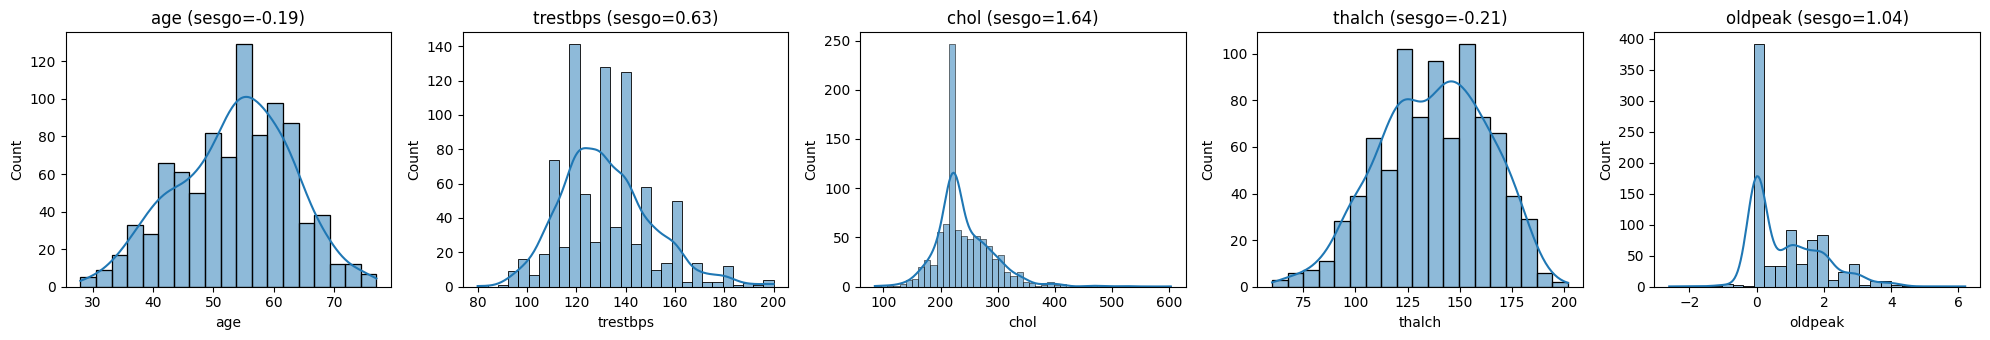

In [7]:
# Histogramas para apoyar la interpretación del sesgo
fig, axes = plt.subplots(1, len(cols_num), figsize=(4 * len(cols_num), 3.5))
for ax, c in zip(axes, cols_num):
    sns.histplot(cardio_df[c].dropna(), kde=True, ax=ax)
    ax.set_title(f'{c} (sesgo={cardio_df[c].skew():.2f})')
plt.tight_layout(); plt.show()

In [8]:
# 3.2 Categóricas
cols_cat = cardio_df.select_dtypes(exclude='number').columns.tolist()
display(cardio_df[cols_cat].describe().T)

for c in cols_cat:
    tabla = pd.concat([
        cardio_df[c].value_counts(dropna=False).rename('frecuencia'),
        (cardio_df[c].value_counts(dropna=False, normalize=True) * 100).round(2).rename('porcentaje (%)')
    ], axis=1)
    print(f'===== {c} ====='); print(tabla, '\n')

,count,unique,top,freq
sex,918,2,Male,724
origin,918,4,Cleveland,304
cp,918,4,asymptomatic,495
fbs,829,2,False,691
restecg,918,3,normal,551
exang,863,2,False,526
slope,610,3,flat,345
ca,309,4,0,181
thal,434,3,normal,196
num,918,5,0,411


===== sex =====
        frecuencia  porcentaje (%)
sex                               
Male           724           78.87
Female         194           21.13 

===== origin =====
               frecuencia  porcentaje (%)
origin                                   
Cleveland             304           33.12
Hungary               292           31.81
VA Long Beach         200           21.79
Switzerland           122           13.29 

===== cp =====
                 frecuencia  porcentaje (%)
cp                                         
asymptomatic            495           53.92
non-anginal             204           22.22
atypical angina         174           18.95
typical angina           45            4.90 

===== fbs =====
       frecuencia  porcentaje (%)
fbs                              
False         691           75.27
True          138           15.03
NaN            89            9.69 

===== restecg =====
                  frecuencia  porcentaje (%)
restecg                            


**Variables numéricas**

| Variable | Media | Mediana | Desv. est. | Rango | Sesgo | Curtosis | Interpretación |
|---|---|---|---|---|---|---|---|
| `age` | 53.5 | 54 | 9.4 | 28–77 | -0.19 | -0.38 | Aproximadamente simétrica y ligeramente platicúrtica (colas ligeras). |
| `trestbps` | 132.3 | 130 | 18.5 | 80–200 | 0.63 | 0.63 | Sesgo positivo moderado: cola hacia valores hipertensivos. |
| `chol` | 242.2 | 223 | 53.4 | 85–603 | **1.64** | **6.57** | Fuerte sesgo positivo y leptocúrtica. |
| `thalch` | 137.5 | 140 | 26.0 | 60–202 | -0.21 | -0.48 | Casi simétrica, con ligera cola hacia frecuencias bajas. |
| `oldpeak` | 0.88 | 0.5 | 1.09 | -2.6–6.2 | 1.04 | 1.12 | Sesgo positivo: la mayoría sin depresión del ST (≈0) y cola hacia valores patológicos. |

- `chol` es la variable con mayor sesgo (1.64) y curtosis (6.57). El sesgo positivo indica que la mayoría de los pacientes se concentra entre 200 y 270 mg/dl, mientras que un grupo reducido presenta valores muy elevados (hasta 603 mg/dl) que alargan la cola derecha y desplazan la media (242.2) por encima de la mediana (223). La curtosis alta confirma colas pesadas, es decir, más valores extremos de los esperados en una distribución normal. Desde una perspectiva clinica esto es consistente con un subgrupo con hipercolesterolemia severa. Además, la mediana (223) está muy próxima al Q1 (216), lo que indica una concentración inusual de observaciones en ese rango. Esto implica que la mediana es un estimador de tendencia central más robusto que la media para esta variable.
- `oldpeak` incluye valores negativos (mínimo -2.6), que representan elevación del segmento ST en lugar de depresión.

**Variables categóricas**

Se observaron desbalances relevantes:
- **`sex`:** 78.9 % hombres frente a 21.1 % mujeres. El modelo aprenderá principalmente de pacientes masculinos, lo que puede limitar su capacidad de generalización a mujeres.
- **`cp`:** 53.9 % de los pacientes son asintomáticos, mientras que la angina típica solo representa 4.9 %. Es un patrón conocido de este conjunto de datos.
- **`fbs`:** 75.3 % con glucosa en ayunas ≤ 120 mg/dl.
- **`restecg`:** 60.0 % normal; hipertrofia ventricular izquierda (20.5 %) y anomalía ST-T (19.5 %) tienen proporciones similares.
- **`origin`:** Cleveland (33.1 %) y Hungary (31.8 %) dominan, Switzerland aporta solo 13.3 %.
- **`num` (target):** 44.8 % sanos (0) frente a 55.2 % con algún grado de enfermedad, lo que es un balance aceptable en formulación binaria. En formulación multiclase, el grado 4 solo representa 3.05 %, un desbalance severo que requeriría estrategias como ponderación de clases o *resampling*.
- Las tablas de frecuencia también revelan una alta proporción de faltantes en `ca` (66.3 %), `thal` (52.7 %) y `slope` (33.6 %).

4. Calcula el porcentaje de valores faltantes en cada columna.
* Elimina aquellas columnas cuyo porcentaje de valores faltantes supere el 30%.
* Crea un mapa de calor que visualice la distribución de los valores faltantes en todas las columnas restantes.
* Algunas variables presentan valores faltantes de manera simultánea; es decir, en el mapa se pueden identificar filas donde varias están ausentes al mismo tiempo. Enumera cuáles son dichas variables e investiga si esta concurrencia tiene sentido desde un punto de vista médico o clínico.

In [9]:
# 4.1 Porcentaje de faltantes por columna
faltantes = pd.DataFrame({'n_faltantes': cardio_df.isna().sum(),
                          'pct_faltantes': (cardio_df.isna().mean() * 100).round(2)})
faltantes.sort_values('pct_faltantes', ascending=False)

,n_faltantes,pct_faltantes
ca,609,66.34
thal,484,52.72
slope,308,33.55
fbs,89,9.69
oldpeak,62,6.75
trestbps,59,6.43
thalch,55,5.99
exang,55,5.99
chol,30,3.27
sex,0,0.00


In [10]:
# 4.2 Eliminar columnas con más de 30 % de faltantes
cols_a_eliminar = faltantes.index[faltantes['pct_faltantes'] > 30].tolist()
print('Columnas eliminadas:', cols_a_eliminar)
cardio_df = cardio_df.drop(columns=cols_a_eliminar)
print('Dimensiones resultantes:', cardio_df.shape)

Columnas eliminadas: ['slope', 'ca', 'thal']
Dimensiones resultantes: (918, 12)


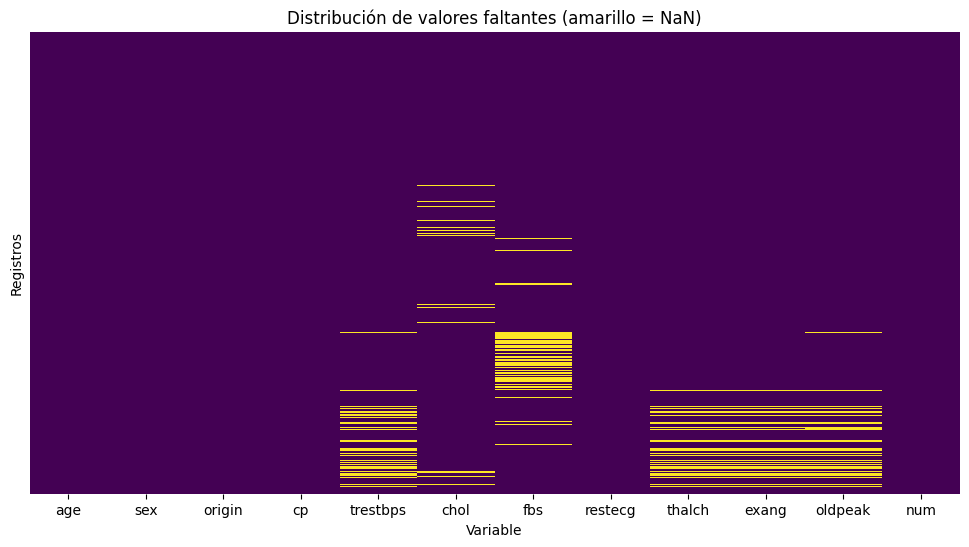

In [11]:
# 4.3 Mapa de calor de faltantes
plt.figure(figsize=(12, 6))
sns.heatmap(cardio_df.isna(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Distribución de valores faltantes (amarillo = NaN)')
plt.xlabel('Variable'); plt.ylabel('Registros')
plt.show()

,faltantes_totales,coinciden_con_thalch
trestbps,59,55
chol,30,3
fbs,89,0
thalch,55,55
exang,55,55
oldpeak,62,54


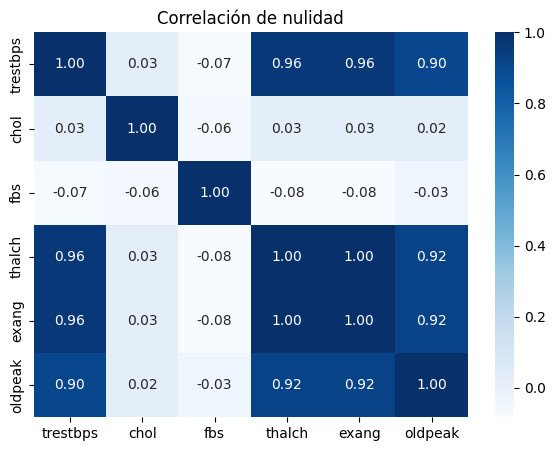

origin,Cleveland,Hungary,Switzerland,VA Long Beach,All
row_0,,,,,
False,304,292,121,147,864
True,0,0,1,53,54
All,304,292,122,200,918


In [12]:
# 4.4 Evidencia cuantitativa: ¿qué faltantes coinciden con los de thalch?
cols_con_na = cardio_df.columns[cardio_df.isna().any()]
bm = cardio_df['thalch'].isna()
display(pd.DataFrame({'faltantes_totales': cardio_df[cols_con_na].isna().sum(),
                      'coinciden_con_thalch': cardio_df.loc[bm, cols_con_na].isna().sum()}))

# Correlación de nulidad entre variables
plt.figure(figsize=(7, 5))
sns.heatmap(cardio_df[cols_con_na].isna().astype(int).corr(), annot=True, fmt='.2f', cmap='Blues')
plt.title('Correlación de nulidad'); plt.show()

# ¿De qué centro vienen los registros con faltantes simultáneos?
patron = cardio_df[['thalch', 'exang', 'oldpeak', 'trestbps']].isna().all(axis=1)
pd.crosstab(patron, cardio_df['origin'], margins=True)

**Porcentaje de faltantes:** `ca` (66.34 %), `thal` (52.72 %), `slope` (33.55 %), `fbs` (9.69 %), `oldpeak` (6.75 %), `trestbps` (6.43 %), `thalch` (5.99 %), `exang` (5.99 %) y `chol` (3.27 %). Las variables `age`, `sex`, `origin`, `cp`, `restecg` y `num` están completas.

**Columnas eliminadas (> 30 %):** `ca`, `thal` y `slope`. Con más de un tercio de la información ausente, imputarlas introduciría más ruido y sesgo que información. El dataframe resultante tiene 918 registros y 12 columnas.

**Variables con faltantes simultáneos:** el mapa de calor muestra que **`thalch`, `exang`, `oldpeak` y `trestbps`** tienen valores ausentes en las mismas filas:

- Los 55 faltantes de `thalch` coinciden con 55 de `exang`, 55 de `trestbps` y 54 de `oldpeak`.
- La correlación de nulidad entre ellas es de 0.90 a 1.00.
- 54 registros tienen las cuatro variables ausentes a la vez, y **53 de ellos provienen de VA Long Beach**.
- `fbs` y `chol` siguen patrones distintos: los faltantes de `fbs` se concentran en Switzerland (74 de 89).

**¿Tiene sentido clínico esta concurrencia? Sí.**
- `thalch` (frecuencia cardíaca máxima alcanzada), `exang` (angina inducida por ejercicio) y `oldpeak` (depresión del ST inducida por ejercicio respecto al reposo) son **tres resultados de una misma prueba: la prueba de esfuerzo** (ECG de esfuerzo o ergometría). Si la prueba no se realizó, no se registró o no se completó, los tres valores faltan de forma conjunta.
- `trestbps` (presión arterial en reposo) también forma parte del protocolo estándar de esa prueba, ya que la presión basal se mide en reposo justo antes de iniciar el ejercicio (Fletcher et al., 2013). Por eso es razonable que se registre en el mismo reporte y se pierda junto con las otras variables.
- Clínicamente, la prueba de esfuerzo puede omitirse por contraindicaciones (angina inestable o hipertensión severa no controlada), por incapacidad física del paciente para ejercitarse (más frecuente a mayor edad) o porque un ECG en reposo anormal (depresión del ST basal) vuelve no diagnóstico el ECG de esfuerzo, en cuyo caso se prefieren pruebas con imagen o farmacológicas (Gibbons et al., 2002).
- La concentración en VA Long Beach sugiere además un componente institucional: diferencias en el protocolo o en el registro de datos de ese centro, uno de los cuatro que integraron la base original (Detrano et al., 1989).

5. Si centramos el análisis en una de las variables identificadas en el ejercicio anterior, se puede suponer que los hallazgos obtenidos podrían ser aplicables a las demás variables que presentan un patrón similar.

* ¿Tendrán los valores faltantes de `thalch` relación con alguna otra variable? Analízalo considerando las siguientes columnas:
  *   Numéricas: `age`, `chol`
  *   Categóricas: `restecg`, `cp`

Para ello deberás dividir cada columna en dos grupos: con / sin faltantes en `thalch` y utilizar métodos gráficos y pruebas de hipótesis para ver si hay diferencias significativas.
* Incluye las conclusiones del análisis con los resultados obtenidos.
* Justifica si el mecanismo de faltantes de `thalch` es MCAR (*Missing Completely at Random*) o MAR (*Missing at Random*).

**NOTA**. Puedes reutilizar las funciones `Diagnose_MV_Numerical` y `Diagnose_MV_Categorical` definidas en Hands-On-Prep_Missing_Values.zip. Revisa nuevamente cómo utilizarlas.

In [13]:
from scipy.stats import ttest_ind
def Diagnose_MV_Numerical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    labels=[]
    box_sr = pd.Series('',index = BM_MV.unique())
    for poss in BM_MV.unique():
        BM = BM_MV == poss
        box_sr[poss] = df[BM][str_att_name].dropna()
        labels.append(MV_labels[poss])

    plt.boxplot(box_sr,vert=False)
    plt.yticks([1,2],labels)
    plt.xlabel(str_att_name)
    plt.show()

    plt.figure(figsize=(10,4))

    att_range = (df[str_att_name].min(),df[str_att_name].max())

    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].hist()
        plt.xlim = att_range
        plt.xlabel(str_att_name)
        plt.title(MV_labels[poss])

    plt.show()

    group_1_data = df[BM_MV][str_att_name].dropna()
    group_2_data = df[~BM_MV][str_att_name].dropna()

    p_value = ttest_ind(group_1_data,group_2_data).pvalue

    print('p-value of t-test: {}'.format(p_value))

In [14]:
from scipy.stats import chi2_contingency
def Diagnose_MV_Categorical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    plt.figure(figsize=(10,4))
    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].value_counts().plot.bar()
        plt.title(MV_labels[poss])
    plt.show()

    contigency_table = pd.crosstab(BM_MV,df[str_att_name])
    p_value = chi2_contingency(contigency_table)[1]

    print('p-value of Chi_squared test: {}'.format(p_value))

In [15]:
# Máscara:
BM_MV = cardio_df['thalch'].isna()
print(BM_MV.value_counts())

thalch
False    863
True      55
Name: count, dtype: int64


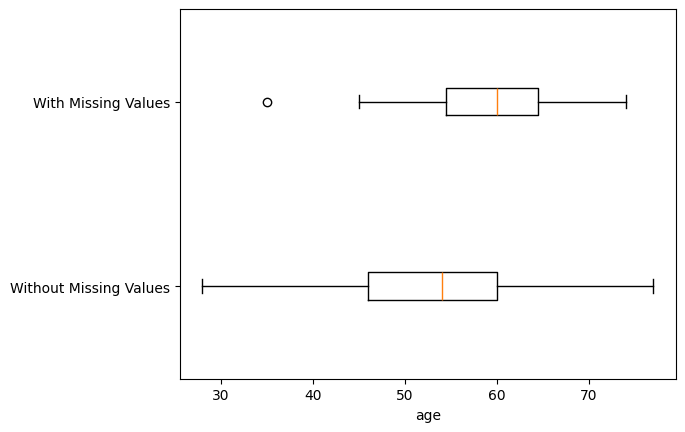

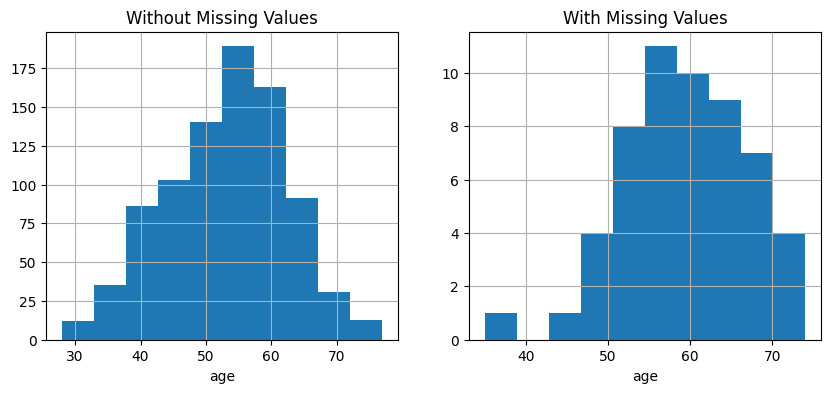

p-value of t-test: 1.5041244185890902e-06


In [16]:
Diagnose_MV_Numerical(cardio_df, 'age', BM_MV)

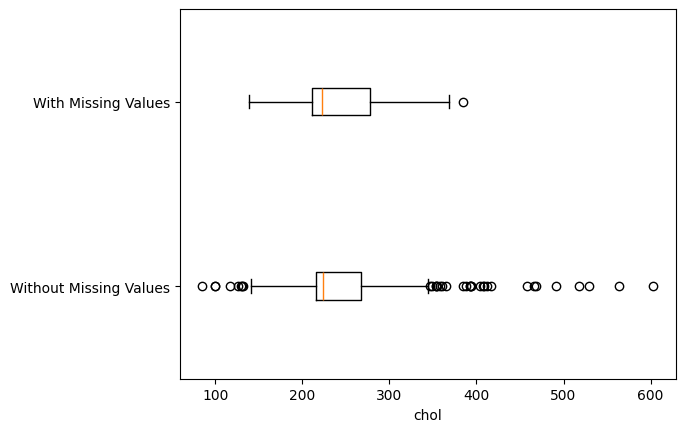

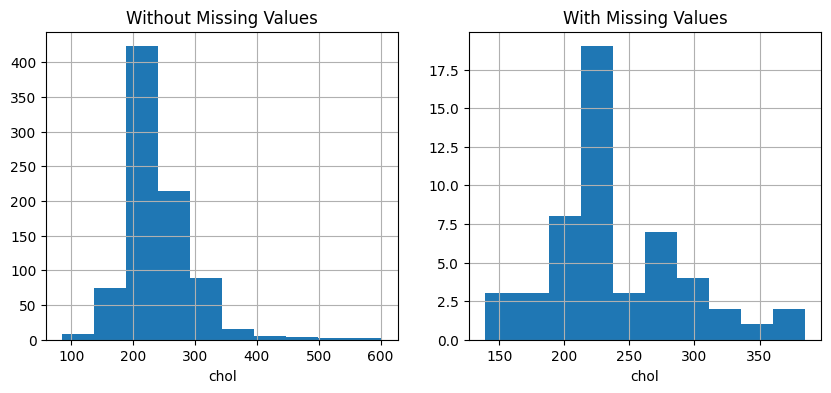

p-value of t-test: 0.7165289974295672


In [17]:
Diagnose_MV_Numerical(cardio_df, 'chol', BM_MV)

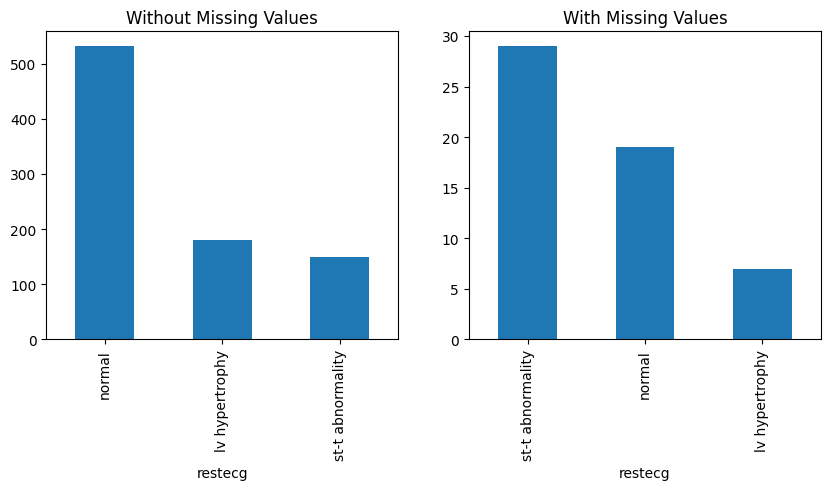

p-value of Chi_squared test: 1.1472889573985467e-09


In [18]:
Diagnose_MV_Categorical(cardio_df, 'restecg', BM_MV)

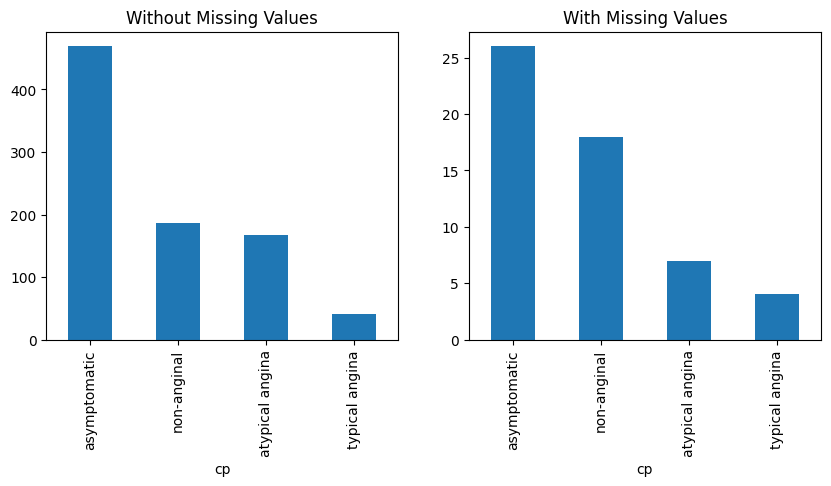

p-value of Chi_squared test: 0.15420097177251701


In [19]:
Diagnose_MV_Categorical(cardio_df, 'cp', BM_MV)

In [20]:
from scipy.stats import mannwhitneyu

resumen = []
for c in ['age', 'chol']:
    g1, g2 = cardio_df.loc[BM_MV, c].dropna(), cardio_df.loc[~BM_MV, c].dropna()
    resumen.append({'variable': c, 'prueba': 't de Student', 'p_value': ttest_ind(g1, g2).pvalue,
                    'media con NaN': round(g1.mean(), 1), 'media sin NaN': round(g2.mean(), 1)})
    resumen.append({'variable': c, 'prueba': 't de Welch', 'p_value': ttest_ind(g1, g2, equal_var=False).pvalue})
    resumen.append({'variable': c, 'prueba': 'Mann-Whitney U', 'p_value': mannwhitneyu(g1, g2).pvalue})
for c in ['restecg', 'cp']:
    resumen.append({'variable': c, 'prueba': 'Chi-cuadrada',
                    'p_value': chi2_contingency(pd.crosstab(BM_MV, cardio_df[c]))[1]})

resumen = pd.DataFrame(resumen)
resumen['¿Significativa (α=0.05)?'] = np.where(resumen['p_value'] < 0.05, 'Sí', 'No')
display(resumen.fillna(''))

for c in ['restecg', 'cp']:
    print(f'\nProporción (%) de {c} según faltante en thalch:')
    print((pd.crosstab(BM_MV.rename('thalch_NaN'), cardio_df[c], normalize='index') * 100).round(1))

,variable,prueba,p_value,media con NaN,media sin NaN,¿Significativa (α=0.05)?
0,age,t de Student,1.504124e-06,59.4,53.2,Sí
1,age,t de Welch,4.115876e-07,,,Sí
2,age,Mann-Whitney U,1.757134e-06,,,Sí
3,chol,t de Student,7.165290e-01,239.6,242.4,No
4,chol,t de Welch,7.104716e-01,,,No
5,chol,Mann-Whitney U,5.992776e-01,,,No
6,restecg,Chi-cuadrada,1.147289e-09,,,Sí
7,cp,Chi-cuadrada,1.542010e-01,,,No



Proporción (%) de restecg según faltante en thalch:
restecg     lv hypertrophy  normal  st-t abnormality
thalch_NaN                                          
False                 21.0    61.6              17.4
True                  12.7    34.5              52.7

Proporción (%) de cp según faltante en thalch:
cp          asymptomatic  atypical angina  non-anginal  typical angina
thalch_NaN                                                            
False               54.3             19.4         21.6             4.8
True                47.3             12.7         32.7             7.3


Se dividió cada variable en dos grupos según si `thalch` es faltante (n = 55) o no (n = 863). Se usaron boxplots, histogramas y gráficas de barras como evidencia gráfica, y pruebas de hipótesis con α = 0.05 (H₀: no hay diferencia entre grupos).

| Variable | Prueba | p-value | ¿Diferencia significativa? | Hallazgo |
|---|---|---|---|---|
| `age` | t de Student / Welch / Mann-Whitney | 1.5×10⁻⁶ / 4.1×10⁻⁷ / 1.8×10⁻⁶ | **Sí** | Los pacientes sin `thalch` son ~6 años mayores (59.4 vs 53.2 años). |
| `chol` | t de Student / Welch / Mann-Whitney | 0.717 / 0.710 / 0.599 | No | Medias similares (239.6 vs 242.4 mg/dl). |
| `restecg` | Chi-cuadrada | 1.1×10⁻⁹ | **Sí** | La anomalía ST-T pasa de 17.4 % a **52.7 %** en el grupo con faltantes; "normal" baja de 61.6 % a 34.5 %. |
| `cp` | Chi-cuadrada | 0.154 | No | Distribuciones de dolor torácico comparables entre grupos. |

**Conclusiones del análisis**
- La edad y el ECG en reposo difieren de forma significativa entre los grupos. La conclusión es robusta, se mantiene con la prueba de Welch (que no asume varianzas iguales, relevante dado el desbalance 55 vs 863), con la prueba no paramétrica de Mann-Whitney (que no asume normalidad) e incluso aplicando una corrección de Bonferroni por cuatro comparaciones (α = 0.0125).
- El colesterol y el tipo de dolor torácico no muestran diferencias, por lo que la ausencia de `thalch` no se relaciona con ellos.
- Estos hallazgos coinciden con la explicación clínica de la Pregunta 4. A los pacientes de mayor edad y con alteraciones del ST en el ECG basal es más probable que no se les realice la prueba de esfuerzo: los primeros por limitaciones físicas, y los segundos porque la depresión ST basal vuelve poco interpretable el ECG de esfuerzo. A esto se suma el efecto institucional: 53 de los 55 faltantes provienen de VA Long Beach.

**¿MCAR o MAR?**

El mecanismo es **MAR (Missing at Random)**. Bajo MCAR, la probabilidad de ausencia sería independiente de todas las variables, por lo que ambos grupos tendrían distribuciones equivalentes en cualquier variable (Rubin, 1976). Aquí la ausencia de `thalch` depende de variables **observadas** (`age`, `restecg` y `origin`), lo cual descarta MCAR y es consistente con MAR. Cabe señalar que un mecanismo MNAR (ausencia dependiente del propio valor no observado de `thalch`) no puede descartarse por completo solo con datos observados (Little & Rubin, 2019). Sin embargo, la evidencia estadística y clínica apunta a que la ausencia se explica por características observadas del paciente y del centro.

Siguiendo la premisa del ejercicio, este diagnóstico se extiende a `exang`, `oldpeak` y `trestbps`, que comparten el mismo patrón de ausencia.

**Implicaciones:**

Eliminar las filas con faltantes sesgaría la muestra, porque se perderían desproporcionadamente pacientes mayores, con ECG anormal y del centro VA Long Beach. Por ello conviene imputar condicionando en variables relacionadas.

6. La imputación de una variable con valores faltantes puede realizarse por grupos o segmentos relevantes. Esto significa que, en lugar de utilizar una estadística global de toda la columna, se calcula la estadística correspondiente dentro de cada grupo definido por otra variable, haciendo:

> `df['var_with_missing'] = df.groupby('related_var')['var_with_missing'].transform(lambda x: x.fillna(x.median()))`

* Utiliza la variable `restecg` para separar los grupos e imputar `thalch` y todas las variables con patrón de faltantes similar (identificadas en el ejercicio 4) Asegúrate de cambiar la función de agregado si hay variables no numéricas.
* Vuelve a generar el mapa de calor para verificar que los valores faltantes en estas variables hayan sido imputados.

In [21]:
# Variables con el mismo patrón de faltantes que thalch
vars_patron_num = ['thalch', 'trestbps', 'oldpeak']
vars_patron_cat = ['exang']

print('Faltantes ANTES:'); print(cardio_df[vars_patron_num + vars_patron_cat].isna().sum())

# Estadísticos por grupo que se usarán para imputar
print('\nMedianas por grupo de restecg:')
print(cardio_df.groupby('restecg', observed=True)[vars_patron_num].median())
print('\nModa de exang por grupo de restecg:')
print(cardio_df.groupby('restecg', observed=True)['exang'].agg(lambda x: x.mode().iloc[0]))

Faltantes ANTES:
thalch      55
trestbps    59
oldpeak     62
exang       55
dtype: int64

Medianas por grupo de restecg:
                  thalch  trestbps  oldpeak
restecg                                    
lv hypertrophy     146.0     130.0      0.8
normal             140.0     130.0      0.2
st-t abnormality   129.0     130.0      0.9

Moda de exang por grupo de restecg:
restecg
lv hypertrophy      False
normal              False
st-t abnormality    False
Name: exang, dtype: category
Categories (2, bool): [False, True]


In [22]:
# Imputación por grupos de restecg
for c in vars_patron_num:
    cardio_df[c] = (cardio_df.groupby('restecg', observed=True)[c]
                    .transform(lambda x: x.fillna(x.median())))

for c in vars_patron_cat:
    cardio_df[c] = (cardio_df.groupby('restecg', observed=True)[c]
                    .transform(lambda x: x.fillna(x.mode().iloc[0])))

print('Faltantes DESPUÉS:'); print(cardio_df[vars_patron_num + vars_patron_cat].isna().sum())

Faltantes DESPUÉS:
thalch      0
trestbps    0
oldpeak     0
exang       0
dtype: int64


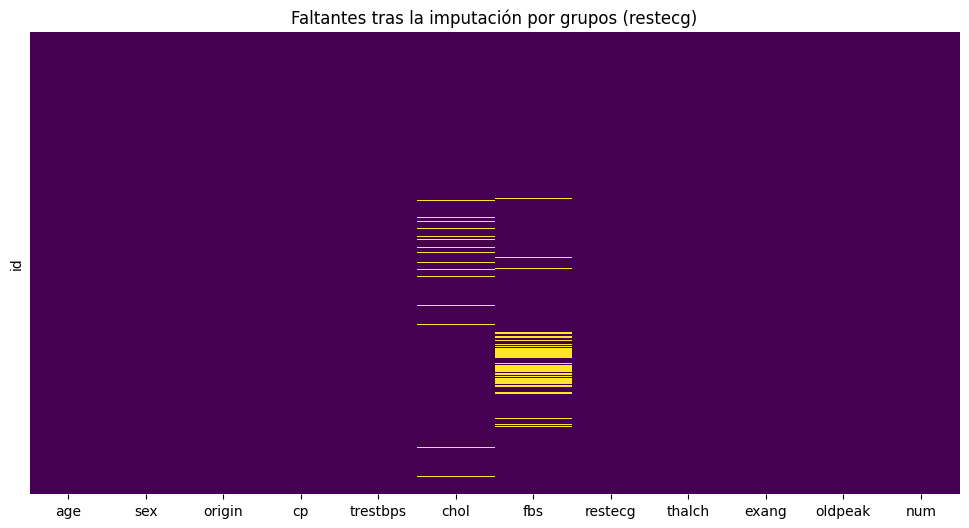

Faltantes restantes:
chol    30
fbs     89
dtype: int64


In [23]:
# Mapa de calor de verificación
plt.figure(figsize=(12, 6))
sns.heatmap(cardio_df.isna(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Faltantes tras la imputación por grupos (restecg)')
plt.show()
print('Faltantes restantes:'); print(cardio_df.isna().sum()[cardio_df.isna().sum() > 0])

Se imputaron por grupos de `restecg` las cuatro variables que comparten el patrón de ausencia identificado en la Pregunta 4. Para las numéricas (`thalch`, `trestbps`, `oldpeak`) se usó la mediana del grupo, por ser robusta ante asimetría y valores atípicos. Para `exang`, al ser categórica (booleana), la función de agregado se cambió a la moda, ya que la mediana no está definida para variables no numéricas.

**Valores utilizados en cada grupo:**

| `restecg` | `thalch` | `trestbps` | `oldpeak` | `exang` (moda) |
|---|---|---|---|---|
| lv hypertrophy | 146 | 130 | 0.8 | False |
| normal | 140 | 130 | 0.2 | False |
| st-t abnormality | 129 | 130 | 0.9 | False |

- **`thalch`** es la variable más sensible a la segmentación: los pacientes con anomalía ST-T alcanzan una frecuencia cardíaca máxima mediana 17 lpm menor que los de hipertrofia ventricular. Esto es relevante porque el 52.7 % de los faltantes de `thalch` pertenece precisamente al grupo ST-T; una mediana global (140) habría sobreestimado sistemáticamente su valor.
- **`oldpeak`** también varía: la depresión del ST es mayor en los grupos con ECG anormal (0.8–0.9) que en el normal (0.2), coherente con su significado clínico.
- **`trestbps`** no cambia entre grupos (130 mm Hg), por lo que en su caso la imputación segmentada equivale a la global.
- **`exang`** tiene moda False en los tres grupos.

Esta estrategia aprovecha que el mecanismo es MAR: al condicionar la imputación en una variable asociada a la ausencia, se reduce el sesgo respecto a una imputación global. Como limitación, cualquier imputación con un valor central reduce artificialmente la varianza; alternativas más sofisticadas serían KNN o imputación múltiple (MICE).

**Verificación:**

El mapa de calor posterior confirma que `thalch`, `trestbps`, `oldpeak` y `exang` ya no tienen valores faltantes. Solo permanecen `chol` (30) y `fbs` (89), cuyo patrón de ausencia es distinto.

7. Para las variables que aún presentan valores faltantes, realiza la imputación utilizando estadísticas generales calculadas sobre toda la columna, sin segmentar por grupos. Esta vez utiliza la clase `SimpleImputer` de sklearn
* Justifica la estrategia (*mean, median, most_frequent*) que emplees en cada caso.


In [24]:
# Diagnóstico para elegir estrategia
print(f"chol -> sesgo = {cardio_df['chol'].skew():.2f}, "
      f"media = {cardio_df['chol'].mean():.1f}, mediana = {cardio_df['chol'].median():.1f}")
print('fbs ->', cardio_df['fbs'].value_counts().to_dict())

chol -> sesgo = 1.64, media = 242.2, mediana = 223.0
fbs -> {False: 691, True: 138}


In [25]:
# chol: numérica asimétrica -> median
imp_mediana = SimpleImputer(strategy='median')
cardio_df[['chol']] = imp_mediana.fit_transform(cardio_df[['chol']])
print('Valor imputado en chol:', imp_mediana.statistics_)

# fbs: categórica -> most_frequent
imp_moda = SimpleImputer(strategy='most_frequent')
cardio_df[['fbs']] = imp_moda.fit_transform(cardio_df[['fbs']].astype(object))
cardio_df['fbs'] = cardio_df['fbs'].astype(bool)
print('Valor imputado en fbs:', imp_moda.statistics_)

print('\nTotal de faltantes en el dataframe:', cardio_df.isna().sum().sum())
cardio_df.info()

Valor imputado en chol: [223.]
Valor imputado en fbs: [False]

Total de faltantes en el dataframe: 0
<class 'pandas.core.frame.DataFrame'>
Index: 918 entries, 1 to 920
Data columns (total 12 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   age       918 non-null    int64   
 1   sex       918 non-null    category
 2   origin    918 non-null    category
 3   cp        918 non-null    category
 4   trestbps  918 non-null    float64 
 5   chol      918 non-null    float64 
 6   fbs       918 non-null    bool    
 7   restecg   918 non-null    category
 8   thalch    918 non-null    float64 
 9   exang     918 non-null    category
 10  oldpeak   918 non-null    float64 
 11  num       918 non-null    category
dtypes: bool(1), category(6), float64(4), int64(1)
memory usage: 82.5 KB


Tras la imputación por grupos solo quedaban faltantes en `chol` (30; 3.27 %) y `fbs` (89; 9.69 %). Se imputaron con `SimpleImputer` usando estadísticas globales de cada columna:

| Variable | Tipo | Estrategia | Valor imputado | Justificación |
|---|---|---|---|---|
| `chol` | Numérica continua | `median` | 223 mg/dl | Distribución fuertemente asimétrica y con colas pesadas. |
| `fbs` | Categórica binaria | `most_frequent` | False | Única estrategia válida para variables no numéricas. |

- **`chol` → `median`:** en la Pregunta 3 se observó un sesgo positivo de 1.64, una curtosis de 6.57 y valores extremos de hasta 603 mg/dl. La media aritmética (242.2) es sensible a esos extremos y queda desplazada hacia la cola derecha, por lo que no representa al paciente típico. La mediana (223) depende solo de la posición central de los datos y es un estimador robusto ante asimetría y valores atípicos. La estrategia `mean` solo sería apropiada con una distribución aproximadamente simétrica.
- **`fbs` → `most_frequent`:** es una variable categórica binaria (glucosa en ayunas > 120 mg/dl: True/False), por lo que la media y la mediana carecen de significado. Se imputa con la moda, False, que representa el 83.4 % de los valores observados (691 de 829). Como limitación, imputar el 9.69 % con un mismo valor incrementa ligeramente la proporción de False y subestima la variabilidad real.

**Verificación:**

El dataframe ya no contiene valores faltantes (918 registros, 12 columnas, 0 NaN).

8. Dibuja boxplots de todas las variables numéricas.
* Obtén los valores atípicos mediante el método gráfico, a partir del objeto devuelto por el boxplot.

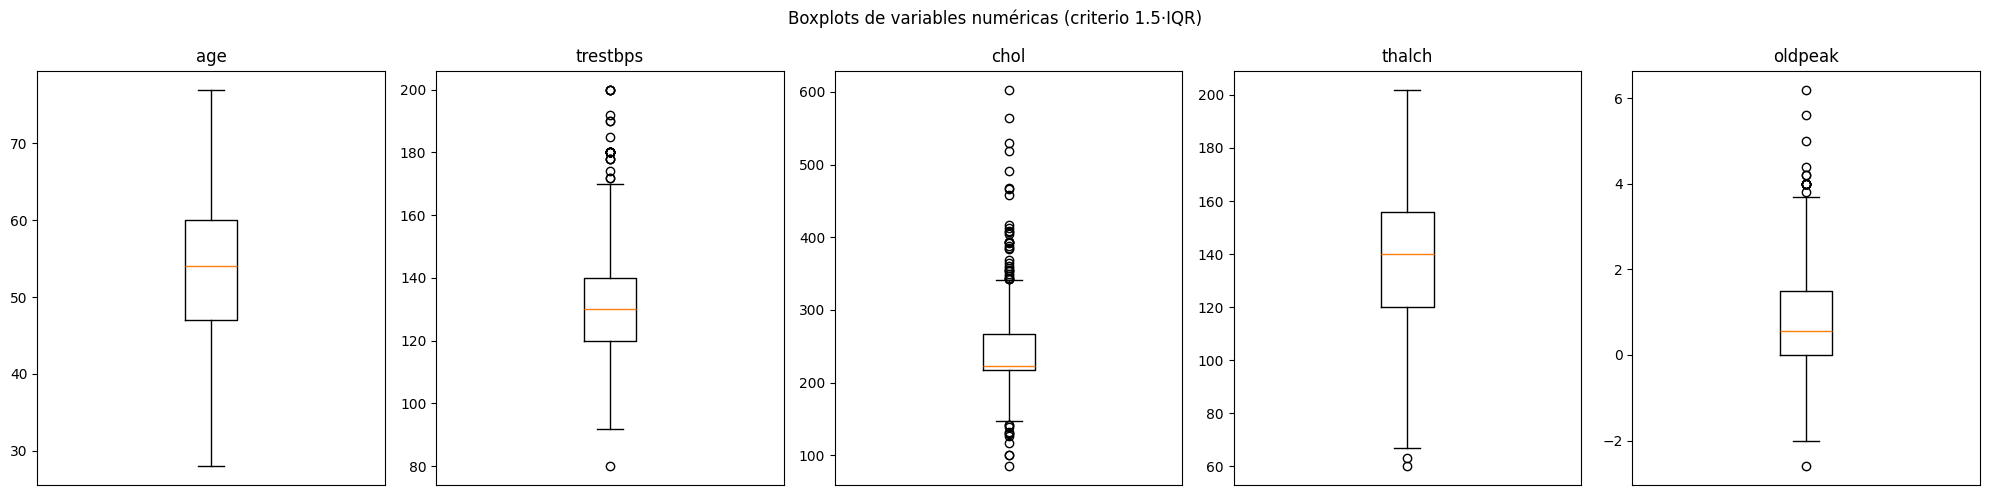

,n_atipicos,% del total
age,0,0.00
trestbps,27,2.94
chol,44,4.79
thalch,2,0.22
oldpeak,16,1.74


age (0 atípicos): []
trestbps (27 atípicos): [80.0, 172.0, 172.0, 174.0, 178.0, 178.0, 178.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 185.0, 190.0, 190.0, 192.0, 200.0, 200.0, 200.0, 200.0]
chol (44 atípicos): [85.0, 100.0, 100.0, 117.0, 126.0, 129.0, 131.0, 132.0, 139.0, 141.0, 142.0, 342.0, 342.0, 342.0, 344.0, 347.0, 349.0, 353.0, 354.0, 355.0, 358.0, 360.0, 365.0, 369.0, 384.0, 385.0, 388.0, 392.0, 393.0, 394.0, 394.0, 404.0, 407.0, 409.0, 412.0, 417.0, 458.0, 466.0, 468.0, 491.0, 518.0, 529.0, 564.0, 603.0]
thalch (2 atípicos): [60.0, 63.0]
oldpeak (16 atípicos): [-2.6, 3.8, 4.0, 4.0, 4.0, 4.0, 4.0, 4.0, 4.0, 4.0, 4.2, 4.2, 4.4, 5.0, 5.6, 6.2]


In [26]:
cols_num = cardio_df.select_dtypes(include='number').columns.tolist()
fig, axes = plt.subplots(1, len(cols_num), figsize=(4 * len(cols_num), 5))

atipicos_graficos = {}
for ax, c in zip(axes, cols_num):
    bp = ax.boxplot(cardio_df[c], whis=1.5)
    ax.set_title(c); ax.set_xticks([])
    atipicos_graficos[c] = np.sort(bp['fliers'][0].get_ydata())
plt.suptitle('Boxplots de variables numéricas (criterio 1.5·IQR)')
plt.tight_layout(); plt.show()

resumen_out = pd.DataFrame({
    'n_atipicos': {c: len(v) for c, v in atipicos_graficos.items()},
    '% del total': {c: round(100 * len(v) / len(cardio_df), 2) for c, v in atipicos_graficos.items()}})
display(resumen_out)
for c, v in atipicos_graficos.items():
    print(f'{c} ({len(v)} atípicos): {v.tolist()}')

Se trazaron boxplots de las cinco variables numéricas. Los atípicos se extrajeron del diccionario que devuelve `plt.boxplot()`, específicamente de `bp['fliers'][0].get_ydata()`, que contiene los puntos ubicados fuera de los bigotes (criterio de Tukey: más allá de Q1 − 1.5·IQR o Q3 + 1.5·IQR).

| Variable | Atípicos | % del total | Valores |
|---|---|---|---|
| `age` | 0 | 0.00 % | — |
| `trestbps` | 27 | 2.94 % | 1 inferior (80) y 26 superiores (172–200 mm Hg) |
| `chol` | 44 | 4.79 % | 11 inferiores (85–142) y 33 superiores (342–603 mg/dl) |
| `thalch` | 2 | 0.22 % | 60 y 63 lpm (inferiores) |
| `oldpeak` | 16 | 1.74 % | 1 inferior (-2.6) y 15 superiores (3.8–6.2) |

**Interpretación**
- `age` no presenta atípicos, consistente con su distribución casi simétrica (sesgo -0.19).
- `chol` concentra la mayor cantidad, en línea con su alta asimetría y curtosis (Pregunta 3). Además, la imputación con la mediana (223) agregó 30 valores al centro de la distribución, lo que estrecha ligeramente el IQR y puede aumentar el número de puntos marcados como atípicos.
- La mayoría de estos valores son **clínicamente plausibles**: presiones sistólicas de 180–200 mm Hg corresponden a crisis hipertensiva; colesterol mayor a 400 mg/dl es compatible con hipercolesterolemia severa o familiar; frecuencias máximas de 60–63 lpm pueden darse en pacientes con incompetencia cronotrópica o bajo tratamiento con betabloqueadores; y una depresión del ST de 4–6 mm indica isquemia importante.
- Por lo tanto, un atípico estadístico no implica necesariamente un error de medición. En un contexto clínico, estos pacientes extremos suelen ser los de mayor riesgo y, por ende, informativos para el modelo. Su eliminación debe justificarse con cuidado.

9. Para la variable `trestbps`, calcula los valores atípicos utilizando el método del rango intercuartílico (IQR).
* Para ello obtén los cuartiles necesarios y determina los límites superior e inferior para filtrar los valores que se encuentren fuera de ese rango.
* Verifica si los resultados coinciden con los obtenidos en el ejercicio anterior.

In [27]:
# Cuartiles e IQR
Q1 = cardio_df['trestbps'].quantile(0.25)
Q3 = cardio_df['trestbps'].quantile(0.75)
IQR = Q3 - Q1
lim_inf = Q1 - 1.5 * IQR
lim_sup = Q3 + 1.5 * IQR
print(f'Q1 = {Q1}, Q3 = {Q3}, IQR = {IQR}')
print(f'Límite inferior = {lim_inf}, Límite superior = {lim_sup}')

# Filtrado de atípicos
mask_out = (cardio_df['trestbps'] < lim_inf) | (cardio_df['trestbps'] > lim_sup)
atipicos_iqr = cardio_df.loc[mask_out, 'trestbps']
print(f'\nAtípicos por IQR: {mask_out.sum()} '
      f'(inferiores: {(cardio_df["trestbps"] < lim_inf).sum()}, '
      f'superiores: {(cardio_df["trestbps"] > lim_sup).sum()})')
atipicos_iqr.sort_values().to_frame().T

Q1 = 120.0, Q3 = 140.0, IQR = 20.0
Límite inferior = 90.0, Límite superior = 170.0

Atípicos por IQR: 27 (inferiores: 1, superiores: 26)


id,645,15,855,173,214,780,184,202,570,485,...,596,890,701,897,339,189,127,549,681,702
trestbps,80.0,172.0,172.0,174.0,178.0,178.0,178.0,180.0,180.0,180.0,...,180.0,180.0,185.0,190.0,190.0,192.0,200.0,200.0,200.0,200.0


In [28]:
# Verificación contra el método gráfico (Pregunta 8)
coinciden = np.array_equal(np.sort(atipicos_iqr.values), atipicos_graficos['trestbps'])
print('Método gráfico:', atipicos_graficos['trestbps'].tolist())
print('Método IQR:    ', np.sort(atipicos_iqr.values).tolist())
print('¿Coinciden ambos métodos?', coinciden)

Método gráfico: [80.0, 172.0, 172.0, 174.0, 178.0, 178.0, 178.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 185.0, 190.0, 190.0, 192.0, 200.0, 200.0, 200.0, 200.0]
Método IQR:     [80.0, 172.0, 172.0, 174.0, 178.0, 178.0, 178.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 185.0, 190.0, 190.0, 192.0, 200.0, 200.0, 200.0, 200.0]
¿Coinciden ambos métodos? True


Cálculo de atípicos de `trestbps` mediante el rango intercuartílico:

| Estadístico | Valor |
|---|---|
| Q1 (percentil 25) | 120 mm Hg |
| Q3 (percentil 75) | 140 mm Hg |
| IQR = Q3 − Q1 | 20 mm Hg |
| Límite inferior = Q1 − 1.5·IQR | **90 mm Hg** |
| Límite superior = Q3 + 1.5·IQR | **170 mm Hg** |

Se identificaron **27 atípicos**: 1 por debajo del límite inferior (80 mm Hg) y 26 por encima del superior (172–200 mm Hg).

**¿Coinciden con el método gráfico? Sí.** `np.array_equal` devuelve `True`: ambos métodos identifican exactamente los mismos 27 valores. Esto ocurre porque `plt.boxplot()` aplica internamente la misma regla de Tukey: con el parámetro por defecto `whis=1.5`, los bigotes se extienden hasta el dato más extremo dentro de [Q1 − 1.5·IQR, Q3 + 1.5·IQR], y todo valor fuera de ese intervalo se dibuja como *flier*. Además, matplotlib y `pandas.quantile()` calculan los cuartiles con el mismo método de interpolación lineal, por lo que los límites resultantes son idénticos. Cabe señalar que los bigotes del boxplot no terminan exactamente en 90 y 170, sino en los datos reales más extremos dentro de ese rango (92 y 170).

10. Elimina los valores atípicos identificados de la variable `trestbps`.
* Dibuja el boxplot final para visualizar la distribución depurada.

In [29]:
# Eliminación de registros con trestbps fuera de los límites IQR
n_antes = len(cardio_df)
cardio_df = cardio_df[(cardio_df['trestbps'] >= lim_inf) & (cardio_df['trestbps'] <= lim_sup)]
print(f'Registros antes: {n_antes} | eliminados: {n_antes - len(cardio_df)} | después: {len(cardio_df)}')
print(f"Rango depurado de trestbps: [{cardio_df['trestbps'].min()}, {cardio_df['trestbps'].max()}]")

Registros antes: 918 | eliminados: 27 | después: 891
Rango depurado de trestbps: [92.0, 170.0]


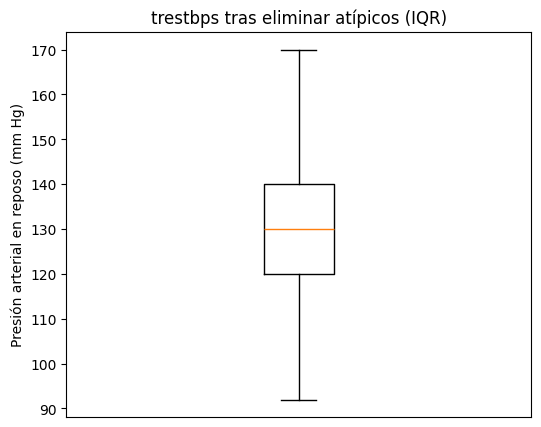

Puntos fuera de bigotes tras recalcular cuartiles: 0
count    891.00
mean     130.71
std       15.73
min       92.00
25%      120.00
50%      130.00
75%      140.00
max      170.00
Name: trestbps, dtype: float64


In [30]:
# Boxplot final
plt.figure(figsize=(6, 5))
bp_final = plt.boxplot(cardio_df['trestbps'], whis=1.5)
plt.title('trestbps tras eliminar atípicos (IQR)')
plt.ylabel('Presión arterial en reposo (mm Hg)'); plt.xticks([])
plt.show()

nuevos = bp_final['fliers'][0].get_ydata()
print(f'Puntos fuera de bigotes tras recalcular cuartiles: {len(nuevos)}')
print(cardio_df['trestbps'].describe().round(2))

Se eliminaron los registros cuyo valor de `trestbps` quedaba fuera del intervalo [90, 170] mm Hg definido en la Pregunta 9.

| | Antes | Después |
|---|---|---|
| Registros | 918 | **891** (−27; 2.94 %) |
| Rango de `trestbps` | 80–200 | 92–170 |
| Media | 132.3* | 130.7 |
| Desviación estándar | 18.5* | 15.7 |
| Q1 / Mediana / Q3 | 120 / 130 / 140 | 120 / 130 / 140 |

(*Valores antes de la imputación, referente a la pregunta 3)

El boxplot final muestra una distribución depurada sin nuevos atípicos. Como los registros eliminados estaban en los extremos, los cuartiles no cambiaron (Q1 = 120, Q3 = 140) y los límites de Tukey se mantienen en 90 y 170 mm Hg, por lo que todos los datos restantes quedan dentro de los bigotes. La desviación estándar se redujo de 18.5 a 15.7 mm Hg, lo que refleja una menor dispersión.

**Consideraciones críticas**
- La eliminación se realizó por filas, lo que implica perder la información completa de 27 pacientes (2.94 % de la muestra), incluidas sus demás variables y su diagnóstico.
- Como se discutió en la Pregunta 8, presiones de 172–200 mm Hg son clínicamente plausibles (crisis hipertensiva) y corresponden a pacientes de alto riesgo cardiovascular, por lo que su exclusión podría reducir la capacidad del modelo para reconocer esos casos. Alternativas menos destructivas serían la "winsorización" (acotar los valores a los límites 90 y 170) o el uso de modelos robustos ante atípicos.
- En la etapa de modelado, este filtrado debería definirse con los límites calculados sobre el conjunto de entrenamiento, para evitar fuga de información.

---

**Declaración de uso de IA**

*   OpenAI. (2026). *ChatGPT (basado en GPT-4)* [Modelo de lenguaje grande], utilizado para investigar conceptos más a fondo y contribuir a las conclusiones de cada punto. https://chat.openai.com

* Anthropic. (2026). *Claude (Opus 5.5)* [Modelo de lenguaje grande], utilizado para generación de código, depuración y apoyo en la redacción e interpretación de resultados especialmente en las celdas con tablas, así como la investigación y citación de fuentes. https://claude.ai/

**Referencias**

* Detrano, R., Janosi, A., Steinbrunn, W., Pfisterer, M., Schmid, J.-J., Sandhu, S., Guppy, K. H., Lee, S., & Froelicher, V. (1989). International application of a new probability algorithm for the diagnosis of coronary artery disease. *The American Journal of Cardiology, 64*(5), 304–310. https://doi.org/10.1016/0002-9149(89)90524-9

* Fletcher, G. F., Ades, P. A., Kligfield, P., Arena, R., Balady, G. J., Bittner, V. A., Coke, L. A., Fleg, J. L., Forman, D. E., Gerber, T. C., Gulati, M., Madan, K., Rhodes, J., Thompson, P. D., & Williams, M. A. (2013). Exercise standards for testing and training: A scientific statement from the American Heart Association. *Circulation, 128*(8), 873–934. https://doi.org/10.1161/CIR.0b013e31829b5b44

* Gibbons, R. J., Balady, G. J., Bricker, J. T., Chaitman, B. R., Fletcher, G. F., Froelicher, V. F., Mark, D. B., McCallister, B. D., Mooss, A. N., O'Reilly, M. G., & Winters, W. L., Jr. (2002). ACC/AHA 2002 guideline update for exercise testing. *Circulation, 106*(14), 1883–1892. https://doi.org/10.1161/01.CIR.0000034670.06526.15

* Little, R. J. A., & Rubin, D. B. (2019). *Statistical analysis with missing data* (3rd ed.). Wiley. https://doi.org/10.1002/9781119482260

* Rubin, D. B. (1976). Inference and missing data. *Biometrika, 63*(3), 581–592. https://doi.org/10.1093/biomet/63.3.581